<a href="https://colab.research.google.com/github/sneharanig06/4NI25CS196_DAV_LAB/blob/main/4NI25CS196_EXP_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('/content/House_Price_dataset.csv')
df=df[df['purpose']=='For Sale']
df=df[['price','bedrooms','baths','Area Size']].dropna()

In [ ]:
df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

In [ ]:
df=df.sample(n=100,random_state=42).reset_index(drop=True)


In [ ]:
X=df[['price','bedrooms','baths','Area Size']]
X_scaled=StandardScaler().fit_transform(X)

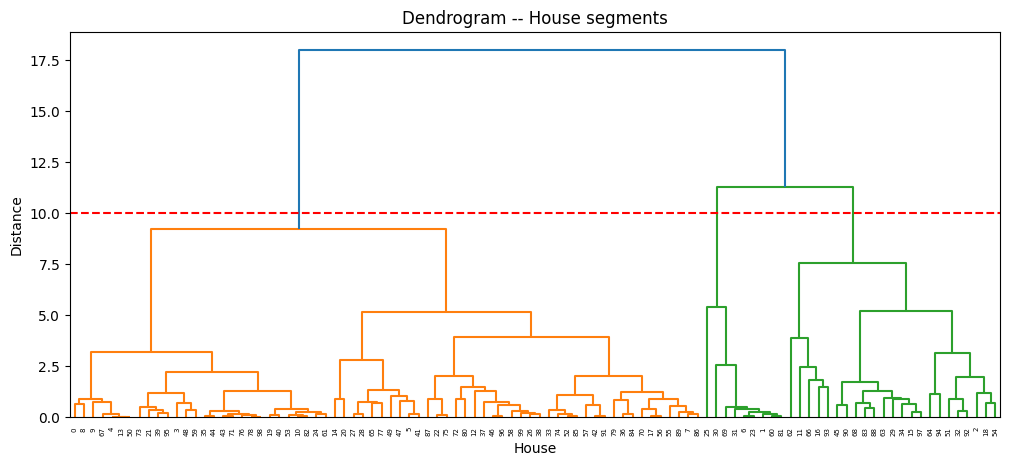

In [ ]:
linked=linkage(X_scaled,method='ward')
plt.figure(figsize=(12,5))
dendrogram(linked)
plt.title('Dendrogram -- House segments')
plt.xlabel('House');plt.ylabel('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

In [ ]:
hc=AgglomerativeClustering(n_clusters=3,linkage='ward')
df['HC_Cluster']=hc.fit_predict(X_scaled)

In [ ]:
print(df['HC_Cluster'].value_counts())
print(df.groupby('HC_Cluster').mean().round(2))

HC_Cluster
0    68
1    23
2     9
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0            9099073.53      2.82   2.93       4.86
1           25865217.39      5.65   5.91       9.58
2           53166666.67      5.22   6.11       1.11


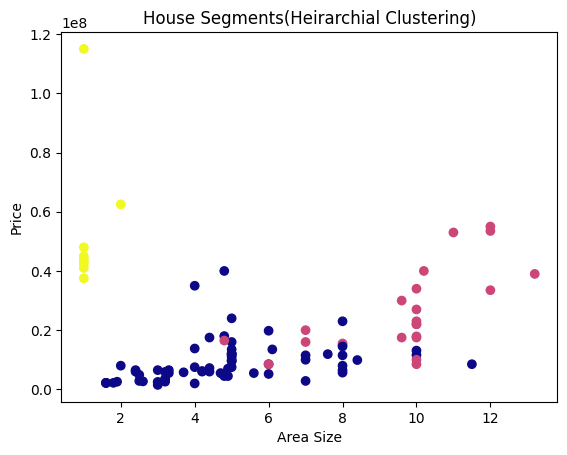

In [ ]:
plt.scatter(df["Area Size"], df["price"], c=df["HC_Cluster"],cmap='plasma')
plt.xlabel("Area Size")
plt.ylabel("Price")
plt.title("House Segments(Heirarchial Clustering)")
plt.show()